In [301]:
!pip install osmnx mapclassify

In [302]:
import geopandas as gpd

filez = "https://github.com/freddyinocente/entrega2/raw/refs/heads/main/2020_Census_Tracts_Seattle.zip"
seattle = gpd.read_file(filez)
seattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


In [303]:
seattle

,GEOID20,GROSS_ACRE,LAND_ACRES,WATER_ACRE,NAME,TRACT_NUMB,BASENAME,UVDA_AREA,CRA_NO,CRA_GRP,GEN_ALIAS,DETL_NAMES,C_DISTRICT,geometry
0,53033000402,444.493643,444.527261,0.000000,Census Tract 4.02,402,4.02,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1267598.433 267477.138, 1267788.924 ..."
1,53033000403,180.930716,165.408389,15.535762,Census Tract 4.03,403,4.03,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1265848.993 271492.767, 1265842.812 ..."
2,53033000700,319.838996,319.862596,0.000000,Census Tract 7,700,7,Lake City,8.2,8,Olympic Hills/Victory Heights,"Lake City, Victory Heights, Olympic Hills, Pin...",5,"POLYGON ((1277629.018 265876.292, 1277833.975 ..."
3,53033003302,154.942826,154.952619,0.000000,Census Tract 33.02,3302,33.02,Ballard,10.2,10,Whittier Heights,"Whittier Heights, Loyal Heights, Crown Hill",6,"POLYGON ((1262877.612 251639.607, 1262891.039 ..."
4,53033003601,166.571397,166.583375,0.000000,Census Tract 36.01,3601,36.01,Green Lake - Roosevelt,9.4,9,Green Lake,"Green Lake, Meridian, Roosevelt, Woodland Park",6,"POLYGON ((1274839.167 250046.877, 1274833.189 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,53033008101,68.690415,66.798515,68.613998,Census Tract 81.01,8101,81.01,Center City,13.2,13,Downtown Commercial Core,"Downtown Commercial Core, West Edge, Central B...",7,"POLYGON ((1268688.847 226501.062, 1268841.791 ..."
173,53033010401,402.739919,402.750637,0.000000,Census Tract 104.01,10401,104.01,Othello,3.5,3,Beacon Hill,Beacon Hill,2,"POLYGON ((1279994.827 207985.661, 1280136.282 ..."
174,53033011401,304.713408,304.719237,0.000000,Census Tract 114.01,11401,114.01,Westwood-Highland Park,2.4,2,Roxhill/Westwood,"Roxhill, Westwood, South Delridge, White Center",1,"POLYGON ((1264535.644 198387.214, 1264519.606 ..."
175,53033011700,868.762098,868.775078,0.000000,Census Tract 117,11700,117,Rainier Beach,3.4,3,South Beacon Hill/NewHolly,"South Beacon Hill, NewHolly, Holly Park",2,"POLYGON ((1280795.738 197846.082, 1280877.933 ..."


In [386]:
seattle.crs

<Projected CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...>
Name: NAD83(HARN) / Washington North (ftUS)
Axis Info [cartesian]:
- [east]: Easting (US survey foot)
- [north]: Northing (US survey foot)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Lambert Conic Conformal (2SP)
Datum: NAD83 (High Accuracy Reference Network)
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

**Preprocesamiento de datos obtenidos mediante crowdsourcing**

In [305]:
# Consigue gasolineras en Seattle
import osmnx as ox

stations = ox.features_from_place("Seattle, Washington, USA",
                                tags={'amenity': 'fuel'})

In [306]:
stations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

In [307]:
stations.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [308]:
stations

geometry amenity  \
element id                                                                      
node    457773031                         POINT (-122.39997 47.63939)    fuel   
        631386821                          POINT (-122.3203 47.62518)    fuel   
        771801423                         POINT (-122.35525 47.73205)    fuel   
        1197964284                        POINT (-122.32958 47.58001)    fuel   
        1489962206                        POINT (-122.32805 47.66483)    fuel   
...                                                               ...     ...   
way     684913608   POLYGON ((-122.37612 47.5448, -122.37623 47.54...    fuel   
        727276570   POLYGON ((-122.33603 47.53219, -122.33603 47.5...    fuel   
        940949039   POLYGON ((-122.26383 47.68144, -122.26394 47.6...    fuel   
        1106778201  POLYGON ((-122.30916 47.57672, -122.30956 47.5...    fuel   
        1460417274  POLYGON ((-122.29762 47.5779, -122.29746 47.57...    fuel   

                       brand brand:wikidata                          name  \
element id                                                                  
node    457773031    Chevron        Q319642              Magnolia Chevron   
        631386821         76       Q1658320                            76   
        771801423    Chevron        Q319642                       Chevron   
        1197964284     Shell     Q110716465                         Shell   
        1489962206  7-Eleven        Q259340                      7-Eleven   
...                      ...            ...                           ...   
way     684913608        NaN            NaN  Gasco & South Seattle Market   
        727276570      Shell     Q110716465                       Shree's   
        940949039   7-Eleven        Q259340                      7-Eleven   
        1106778201  Sinclair            NaN                           NaN   
        1460417274      Arco        Q304769                          Arco   

                   addr:city addr:housenumber addr:postcode  \
element id                                                    
node    457773031        NaN              NaN           NaN   
        631386821    Seattle              915         98102   
        771801423        NaN              NaN           NaN   
        1197964284       NaN              NaN           NaN   
        1489962206       NaN              NaN           NaN   
...                      ...              ...           ...   
way     684913608        NaN              NaN           NaN   
        727276570    Seattle              140         98106   
        940949039        NaN              NaN           NaN   
        1106778201       NaN              NaN           NaN   
        1460417274       NaN              NaN           NaN   

                                addr:street  check_date  ... start_date  \
element id                                               ...              
node    457773031                       NaN         NaN  ...        NaN   
        631386821           East Roy Street  2024-08-13  ...        NaN   
        771801423                       NaN         NaN  ...        NaN   
        1197964284                      NaN         NaN  ...        NaN   
        1489962206                      NaN  2026-02-18  ...        NaN   
...                                     ...         ...  ...        ...   
way     684913608                       NaN         NaN  ...        NaN   
        727276570   Southwest Kenyon Street         NaN  ...        NaN   
        940949039                       NaN         NaN  ...        NaN   
        1106778201                      NaN         NaN  ...        NaN   
        1460417274                      NaN         NaN  ...        NaN   

                   fuel:e85 maxheight contact:facebook contact:instagram  \
element id                                                                 
node    457773031       NaN       NaN              NaN   

In [309]:
stations.index

MultiIndex([('node',  457773031),
            ('node',  631386821),
            ('node',  771801423),
            ('node', 1197964284),
            ('node', 1489962206),
            ('node', 2266423106),
            ('node', 2702032640),
            ('node', 2702054487),
            ('node', 2995124967),
            ('node', 5283345524),
            ...
            ( 'way',  600101678),
            ( 'way',  600101691),
            ( 'way',  600101760),
            ( 'way',  603557992),
            ( 'way',  616232144),
            ( 'way',  684913608),
            ( 'way',  727276570),
            ( 'way',  940949039),
            ( 'way', 1106778201),
            ( 'way', 1460417274)],
           names=['element', 'id'], length=128)

In [310]:
stations.reset_index(drop=False,inplace=True)
stations.head()

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
0,node,457773031,POINT (-122.39997 47.63939),fuel,Chevron,Q319642,Magnolia Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node,631386821,POINT (-122.3203 47.62518),fuel,76,Q1658320,76,Seattle,915,98102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node,771801423,POINT (-122.35525 47.73205),fuel,Chevron,Q319642,Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node,1197964284,POINT (-122.32958 47.58001),fuel,Shell,Q110716465,Shell,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node,1489962206,POINT (-122.32805 47.66483),fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [311]:
colsToKeep=['element','name','geometry']
fuelSeattle=stations[colsToKeep].copy()

In [390]:
Seattle_crs = "EPSG:2926"

fuelSeattle = fuelSeattle.to_crs(Seattle_crs)

In [391]:
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 128 entries, 0_Magnolia Chevron to 127_Arco
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   geometry  128 non-null    geometry
dtypes: geometry(1), object(1)
memory usage: 7.1+ KB


In [314]:
fuelSeattle.fillna({'name':'Unknown'},inplace=True)

In [315]:
fuelSeattle.index.astype(str)+"_"+fuelSeattle.name

,0
0,0_Magnolia Chevron
1,1_76
2,2_Chevron
3,3_Shell
4,4_7-Eleven
...,...
123,123_Gasco & South Seattle Market
124,124_Shree's
125,125_7-Eleven
126,126_Unknown


In [316]:
fuelSeattle['newname']=fuelSeattle.index.astype(str)+"_"+fuelSeattle.name
fuelSeattle.set_index('newname',inplace=True)
fuelSeattle.drop(columns=['name'],inplace=True)
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (1254225.808 237157.075)
1_76,node,POINT (1273761.825 231586.412)
2_Chevron,node,POINT (1265915.805 270730.794)
3_Shell,node,POINT (1271154.457 215156.435)
4_7-Eleven,node,POINT (1272132.654 246082.805)


In [317]:
import pandas as pd

pd.crosstab(fuelSeattle.element,fuelSeattle.geometry.geom_type, margins=True)

col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


In [318]:
#original data
stations[stations.element=='relation']

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source


/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

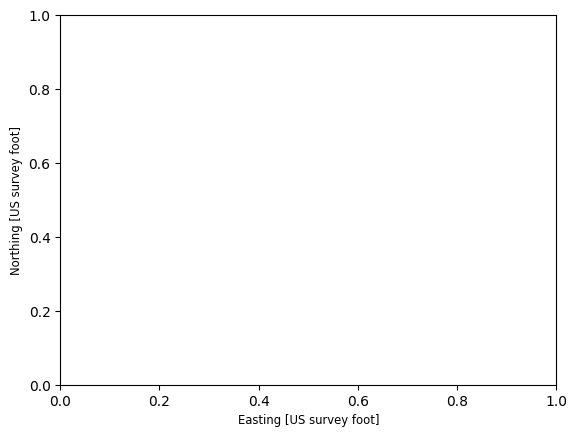

In [395]:
fuelSeattle[fuelSeattle.element=='relation'].plot()

In [320]:
schools = ox.features_from_place("Seattle, Washington, USA",
                                tags={'amenity': 'school'})
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

In [321]:
schools.reset_index(inplace=True)
schoolSeattle=schools[['element','name','geometry']].copy()
schoolSeattle.fillna({'name':'Unknown'},inplace=True)
schoolSeattle['newname']=schoolSeattle.index.astype(str)+"_"+schoolSeattle.name
schoolSeattle.set_index('newname',inplace=True)
schoolSeattle.drop(columns=['name'],inplace=True)
schoolSeattle = schoolSeattle.to_crs(Seattle_crs)
schoolSeattle.head()


,element,geometry
newname,,
0_Mapleleaf School,node,POINT (1280636.199 259250.884)
1_Hazel Wolf K-8,node,POINT (1273664.079 250588.262)
2_Epic Life Academy,node,POINT (1269088.863 260916.396)
3_Christ the King Elementary School,node,POINT (1266288.637 263963.415)
4_Assumption Saint Bridget School,node,POINT (1280842.038 249445.989)


In [322]:
pd.crosstab(schoolSeattle.element,schoolSeattle.geometry.geom_type, margins=True)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


In [323]:
schools[(schools.element=='relation') & (schools.geometry.geom_type=='MultiPolygon')]

,element,id,geometry,amenity,check_date,ele,gnis:feature_id,name,addr:city,addr:housenumber,...,building:levels,fax,short_name,start_date,addr:housename,nursery,preschool,school:language,layer,type
54,relation,537423,"MULTIPOLYGON (((-122.2931 47.57649, -122.29298...",school,NaN,28,1505026,Franklin High School,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
56,relation,4764405,"MULTIPOLYGON (((-122.31777 47.64223, -122.3176...",school,NaN,62,1515690,Seattle Preparatory School,Seattle,2400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
57,relation,7616973,"MULTIPOLYGON (((-122.33765 47.69496, -122.3376...",school,NaN,NaN,NaN,Cascadia Elementary School,Seattle,1700,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
59,relation,18609000,"MULTIPOLYGON (((-122.26364 47.67391, -122.2636...",school,NaN,NaN,NaN,Sand Point Elementary School,Seattle,6208,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

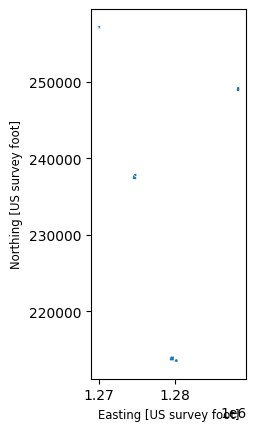

In [324]:
schoolSeattle[(schoolSeattle.element=='relation') & (schoolSeattle.geometry.geom_type=='MultiPolygon')].plot()

In [325]:
base=seattle.explore(tiles='cartodbpositron',color='lightblue')
schoolSeattle.explore(m=base,color='k')
fuelSeattle.explore(m=base,color='red')

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [326]:
base=seattle.explore(tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)'
)
schoolSeattle.explore(m=base,color='k')
fuelSeattle.explore(m=base,color='red')

EXPLORAR DISTANCIA

In [327]:
D_Matrix_fuel_fuel=fuelSeattle.geometry.apply\
(lambda station: fuelSeattle.geometry.distance(station))

D_Matrix_fuel_fuel

newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Unknown,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,20314.729823,35550.677467,27759.815222,20008.093629,12838.680187,13635.407906,15120.692074,12093.826015,22315.071846,...,36208.925403,26449.648624,27803.139130,37224.558595,27530.905239,34955.908304,42139.231102,36854.688530,31850.657385,33672.825639
1_76,20314.729823,0.000000,39922.959420,16635.580297,14587.652690,24276.203332,9563.080631,29619.987667,18959.534400,7044.047238,...,34467.596388,30468.366283,19128.392368,21605.238851,11457.179454,32360.047029,34103.248242,24761.373684,17800.069179,18006.481671
2_Chevron,35550.677467,39922.959420,0.000000,55820.721476,25419.924886,22776.075200,31771.865294,22916.492383,24608.496922,46601.165070,...,11272.554688,9720.098002,24405.730705,61392.770340,51380.020966,68454.714734,73028.980776,29090.347987,57692.327148,57869.995058
3_Shell,27759.815222,16635.580297,55820.721476,0.000000,30941.837008,37045.540956,24098.489980,41467.923412,32601.003872,9591.657644,...,51059.819848,46142.171971,35706.953072,10522.306000,7101.105546,17207.685974,17478.896002,40362.105888,5015.759084,7886.141057
4_7-Eleven,20008.093629,14587.652690,25419.924886,30941.837008,0.000000,15078.004538,8327.843189,20587.208435,10160.706341,21465.512878,...,20290.587475,16210.674455,7807.262178,35972.850132,26018.238481,45320.742434,48389.796041,16908.677289,32386.786765,32458.113268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,34955.908304,32360.047029,68454.714734,17207.685974,45320.742434,47033.450786,37365.194513,50071.162875,43928.303887,25733.250923,...,65560.466821,58733.777094,51273.577399,23134.261369,24308.661296,0.000000,10899.509356,56953.420717,20090.930863,22811.730052
124_Shree's,42139.231102,34103.248242,73028.980776,17478.896002,48389.796041,53120.795784,41261.151732,56920.329524,49198.923179,27061.307190,...,68538.301409,63298.997667,53112.414419,17702.151329,23518.432218,10899.509356,0.000000,57196.738171,17409.015732,19116.439773
125_7-Eleven,36854.688530,24761.373684,29090.347987,40362.105888,16908.677289,30655.159863,24005.749739,35573.553884,26610.161992,31225.955902,...,18435.227461,24099.157375,9283.249598,41236.716853,33652.681048,56953.420717,57196.738171,0.000000,39712.976461,38514.801673


In [328]:
D_Matrix_fuel_fuel.replace(0,None,inplace=True)
D_Matrix_fuel_fuel.min(axis=1).sort_values().head(10)

,0
newname,
104_ARCO,11.742876
103_ARCO,11.742876
89_76,14.661734
88_76,14.661734
30_Chevron,30.295914
11_Chevron,30.295914
91_Shell,34.529691
90_Shell,34.529691
60_Pacific Pride,40.789138


In [329]:
D_Matrix_fuel_school=fuelSeattle.geometry.apply\
(lambda station: schoolSeattle.geometry.distance(station))

D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,34433.197958,23627.170324,28025.269993,29395.436742,29316.226076,43788.215751,44332.478433,31199.193849,14728.369095,17475.689134,...,45164.480851,29713.873775,23615.739328,47294.861695,40138.681454,10255.493348,44570.733118,13307.450759,33746.966412,34675.661881
1_76,28505.788621,19002.101528,29699.907834,33228.283611,19211.816584,28909.757385,39304.381795,21659.640827,16653.432576,2888.550257,...,30177.185404,21013.021379,19986.298355,33601.452343,35704.213769,12057.012118,40692.082193,8384.204861,28264.477787,22080.215347
2_Chevron,18667.574849,21581.412125,10314.587437,6777.642007,25996.834008,68690.379760,77043.586161,24823.603850,24502.056005,38250.274269,...,69910.728190,23124.495190,20341.952853,73493.117728,16354.833082,31103.220061,77868.334558,40785.422130,17876.251837,61879.297642
3_Shell,45102.370745,35520.594298,45806.557986,49048.929832,35631.766158,16180.750154,22860.104180,38058.107788,31525.568018,17685.331937,...,17552.061178,37538.570396,36451.928205,19549.536206,52313.771431,25105.699497,24451.342844,15688.947681,44883.027446,6918.158588
4_7-Eleven,15675.093321,4758.613701,15142.657561,18811.398946,9336.185967,43271.057643,53108.430771,11204.531034,6305.652652,13276.692433,...,44495.092326,9766.909065,5540.677868,48083.017977,22461.327960,9919.654889,54257.977858,17432.166354,15184.712401,36658.519135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,60511.984458,50075.387276,59128.536794,61761.850345,51531.019096,23708.630876,9575.580294,53980.478031,44112.819692,32459.445245,...,24582.146750,53232.887694,50813.804119,23117.164882,67597.481339,37115.314925,9573.741356,27876.054205,60171.044638,17042.881973
124_Shree's,62510.850464,52992.174677,63139.821197,66251.693258,52942.755002,15207.234444,7261.536113,55346.491765,48570.893258,35115.112129,...,15630.837519,54905.126049,53911.551666,13040.846633,69730.371973,41864.889948,9705.538434,32239.715818,62314.069700,12512.025276
125_7-Eleven,10473.836280,14427.654728,21011.373235,24900.510983,7577.776785,47855.655775,63181.388646,6204.483287,22902.817891,25396.100767,...,48766.788053,7191.249431,14974.743429,53024.059572,15755.338730,26427.305417,64812.903630,31378.281377,10744.266574,44033.780713


DECISIÓN 1: ENCONTRAR ESTACIONES QUE DEBEN IRSE

In [330]:
D_Matrix_fuel_school.min(axis=1).sort_values().head(10)

,0
newname,
102_Shell,2.706856
38_Shell,76.332856
69_Shell,120.272228
1_76,246.384904
111_Space Age,299.431472
74_Shell,310.128281
109_Shell,318.525772
96_Chevron,329.267682
36_Chevron,367.747274


In [331]:
mindDist=200

DECISIÓN 2: ASEGURAR EL PERÍMETRO DE CADA ESCUELA

In [332]:
schoolSeattle_buffered=schoolSeattle.buffer(mindDist)
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((1280836.199 259250.884, 1280835.236 ..."
1_Hazel Wolf K-8,"POLYGON ((1273864.079 250588.262, 1273863.116 ..."
2_Epic Life Academy,"POLYGON ((1269288.863 260916.396, 1269287.9 26..."
3_Christ the King Elementary School,"POLYGON ((1266488.637 263963.415, 1266487.674 ..."
4_Assumption Saint Bridget School,"POLYGON ((1281042.038 249445.989, 1281041.075 ..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((1264242.699 239864.838, 1264581.107 ..."
213_Roxhill Elementary School,"POLYGON ((1260366.54 193080.268, 1260366.976 1..."
214_Downtown School,"POLYGON ((1265544.522 230145.39, 1265564.098 2..."


In [333]:
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

In [334]:
secured_schoolSeattle=gpd.GeoDataFrame(geometry=schoolSeattle_buffered)
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((1280836.199 259250.884, 1280835.236 ..."
1_Hazel Wolf K-8,"POLYGON ((1273864.079 250588.262, 1273863.116 ..."
2_Epic Life Academy,"POLYGON ((1269288.863 260916.396, 1269287.9 26..."
3_Christ the King Elementary School,"POLYGON ((1266488.637 263963.415, 1266487.674 ..."
4_Assumption Saint Bridget School,"POLYGON ((1281042.038 249445.989, 1281041.075 ..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((1264242.699 239864.838, 1264581.107 ..."
213_Roxhill Elementary School,"POLYGON ((1260366.54 193080.268, 1260366.976 1..."
214_Downtown School,"POLYGON ((1265544.522 230145.39, 1265564.098 2..."


In [335]:
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


DECISIÓN 3: ESTANDARIZACIÓN DE GEOMETRÍA DE ESTACIONES DE GAS

In [336]:
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


In [337]:
fuelSeattle_allPoly=fuelSeattle.copy()
fuelSeattle_allPoly['geometry'] = [
    station.buffer(10) if station.geom_type == 'Point' else station
    for station in fuelSeattle.geometry
]

In [338]:
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

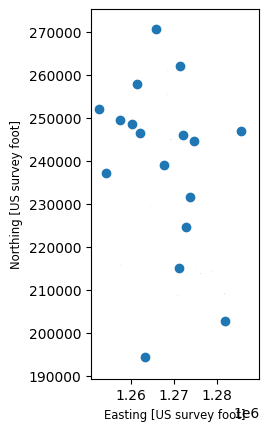

In [339]:
fuelSeattle.plot()


Decisión 4: Superposición (Overlay) o unión espacial (SJoin) para determinar las gasolineras en dificultades

In [340]:
fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='intersection',keep_geom_type=False)

,element,geometry
0,way,"POLYGON ((1279041.377 252522.167, 1279066.628 ..."
1,way,"POLYGON ((1276297.504 228019.575, 1276285.311 ..."
2,way,"POLYGON ((1281755.589 209024.184, 1281635.441 ..."


In [341]:
fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

,element,geometry,newname_right
newname_left,,,
38_Shell,way,"POLYGON ((1279025.98 252522.241, 1279041.377 2...",188_Northwest Montessori School
69_Shell,way,"POLYGON ((1276307.505 228025.22, 1276297.504 2...",116_Morningside Academy
102_Shell,way,"POLYGON ((1281757.098 209127.657, 1281755.589 ...",120_La Escuelita Bilingual School


In [342]:
gas_relocate=fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

In [343]:
is_duplicate = gas_relocate.index.duplicated(keep=False)

gas_relocate[is_duplicate]

,element,geometry,newname_right
newname_left,,,


In [344]:
gas_relocate.reset_index(drop=False).\
drop_duplicates(subset='newname_left').\
set_index('newname_left')

,element,geometry,newname_right
newname_left,,,
38_Shell,way,"POLYGON ((1279025.98 252522.241, 1279041.377 2...",188_Northwest Montessori School
69_Shell,way,"POLYGON ((1276307.505 228025.22, 1276297.504 2...",116_Morningside Academy
102_Shell,way,"POLYGON ((1281757.098 209127.657, 1281755.589 ...",120_La Escuelita Bilingual School


In [345]:
gas_relocate= gas_relocate.reset_index(drop=False).drop_duplicates(subset='newname_left').\
              set_index('newname_left')

In [346]:
base=secured_schoolSeattle.sjoin(gas_relocate,how='inner',predicate='intersects').explore(color='yellow', tiles='cartodbpositron')
gas_relocate.explore(m=base,color='red')

/usr/local/lib/python3.13/dist-packages/geopandas/explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


In [347]:
base=secured_schoolSeattle.sjoin(gas_relocate,how='inner',predicate='intersects').explore(color='yellow', tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)'
)
gas_relocate.explore(m=base,color='red')

DECISIÓN 5: Encontrar un mejor lugar para las estaciones en conflicto

In [401]:

place = "Seattle, Washington, USA"
G = ox.graph_from_place(place, network_type="drive")
streets = ox.graph_to_gdfs(G, nodes=False, edges=True)
streets.shape

(50301, 15)

In [349]:
streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


In [350]:
streets.highway.value_counts().index

Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['unclassified', 'residential'],                      'trunk_link',
                                'busway',         ['secondary', 'tertiary'],
                ['primary', 'secondary'],  ['living_street', 'residential'],
           ['motorway_link', 'motorway'],     ['trunk_link', 'residential'],
            ['unclassified', 'tertiary'],        ['trunk_link', 'tertiary'],
             ['tertiary', 'residential'],       ['residential', 'tertiary'],
       ['secondary_link', 'residential'],    ['secondary_link', 'tertiary'],

In [351]:
GAS_STATION_ROAD_TYPES = [
    'motorway',
    'primary',
    'trunk',
    'motorway_link',
    'primary_link',
    'trunk_link',
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]

suitable_roads = streets[streets.highway.isin(GAS_STATION_ROAD_TYPES)]

suitable_roads.shape

(3709, 15)

In [352]:
suitable_roads = suitable_roads.to_crs(seattle.crs)

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

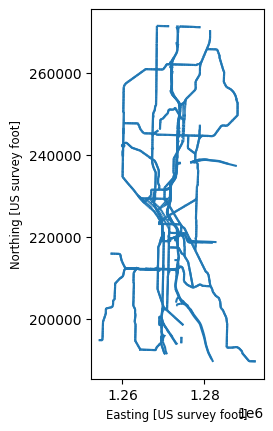

In [353]:
suitable_roads.plot()

In [354]:
competitionDistance=100
fuelSeattle_allPoly_buffered=fuelSeattle_allPoly.buffer(competitionDistance)

In [355]:
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [356]:
secured_fuelSeattle_allPoly=gpd.GeoDataFrame(geometry=fuelSeattle_allPoly_buffered)

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

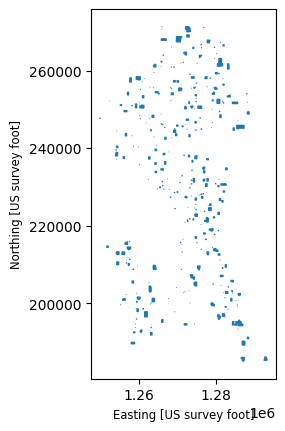

In [357]:
secured_areas_dissolved=secured_fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='union',keep_geom_type=False).dissolve()
secured_areas=gpd.GeoDataFrame(geometry=secured_areas_dissolved.geometry)
secured_areas.plot()

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2883: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.clip(self, mask=mask, keep_geom_type=keep_geom_type, sort=sort)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

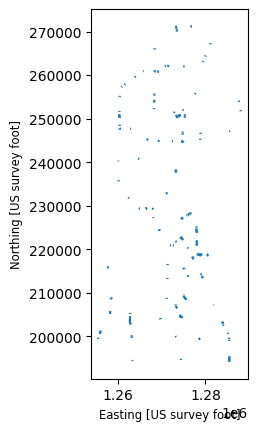

In [358]:
suitable_roads.clip(secured_areas,keep_geom_type=False).plot()

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.overlay(


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

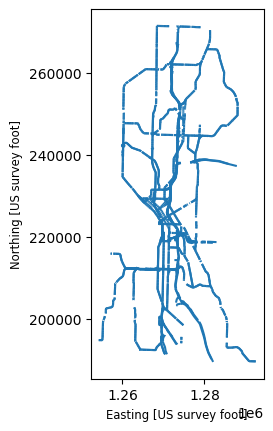

In [359]:
suitable_roads.overlay(secured_areas,keep_geom_type=False, how='difference').plot()

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2680: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.sjoin(


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

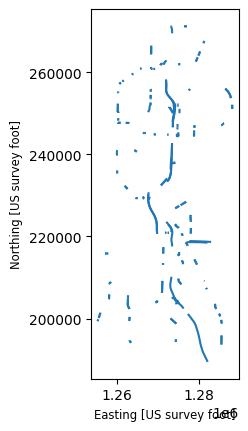

In [360]:
suitable_roads.sjoin(secured_areas, predicate='intersects').plot()

In [361]:
bad_geoms = suitable_roads.clip(secured_areas)
good_segments = suitable_roads.overlay(bad_geoms, how='difference')

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2883: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.clip(self, mask=mask, keep_geom_type=keep_geom_type, sort=sort)


In [362]:
good_routes_forGas_dissolved=suitable_roads.overlay(secured_areas,keep_geom_type=False, how='difference').dissolve()
good_routes_forGas=gpd.GeoDataFrame(geometry=good_routes_forGas_dissolved.geometry)
good_routes_forGas

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.overlay(


,geometry
0,"MULTILINESTRING ((1273281.728 236469.254, 1273..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

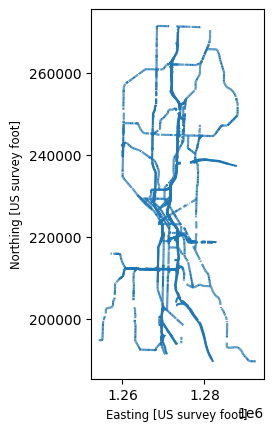

In [363]:
good_routes_forGas.plot()

In [374]:
import random
from shapely.geometry import Point

# Verificar que todo esté en el mismo CRS (los tres deben salir iguales)
print(schoolSeattle.crs)
print(good_routes_forGas.crs)
print(secured_areas.crs)

def random_point_in(gdf):
    geoms = gdf.geometry[~gdf.geometry.is_empty & gdf.geometry.notna()]
    g = geoms.sample(1).iloc[0]
    parts = list(g.geoms) if hasattr(g, "geoms") else [g]

    if parts[0].geom_type == "Point":
        return random.choice(parts)

    if parts[0].geom_type == "LineString":
        lengths = [p.length for p in parts]
        line = random.choices(parts, weights=lengths)[0]
        return line.interpolate(random.random(), normalized=True)

    # polígonos
    poly = random.choices(parts, weights=[p.area for p in parts])[0]
    minx, miny, maxx, maxy = poly.bounds
    for _ in range(1000):
        p = Point(random.uniform(minx, maxx), random.uniform(miny, maxy))
        if poly.contains(p):
            return p
    return poly.representative_point()


potential_Locations=good_routes_forGas.copy()
newPOLYGONS=[]
pointsComputed=1
attempts=1
while pointsComputed<=len(gas_relocate):
  if potential_Locations.empty:
    break
  candidatePoint=gpd.GeoSeries([random_point_in(potential_Locations)], crs=potential_Locations.crs)
  candidateStation=gpd.GeoDataFrame(geometry=candidatePoint.buffer(100))
  if candidateStation.overlay(secured_areas,how='intersection',keep_geom_type=False).empty:
    newPOLYGONS.append(candidateStation)
    pointsComputed+=1
    potential_Locations=potential_Locations.overlay(candidateStation, how='difference', keep_geom_type=False)
  if attempts>len(gas_relocate)*10:
    break
  attempts+=1

attempts,len(newPOLYGONS)

EPSG:2926
PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",47],PARAMETER["central_meridian",-120.833333333333],PARAMETER["standard_parallel_1",47.5],PARAMETER["standard_parallel_2",48.7333333333333],PARAMETER["false_easting",1640416.66666667],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
EPSG:2926


/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.overlay(
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...
Right CRS: EPSG:2926

  return geopandas.overlay(
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2981: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS

(4, 3)

In [375]:
newPOLYGONS

[                                            geometry
 0  POLYGON ((1268131.118 231936.693, 1268130.636 ...,
                                             geometry
 0  POLYGON ((1281025.651 191751.964, 1281025.17 1...,
                                             geometry
 0  POLYGON ((1282984.497 245370.866, 1282984.015 ...]

In [376]:
pd.concat(newPOLYGONS)

,geometry
0,"POLYGON ((1268131.118 231936.693, 1268130.636 ..."
0,"POLYGON ((1281025.651 191751.964, 1281025.17 1..."
0,"POLYGON ((1282984.497 245370.866, 1282984.015 ..."


In [377]:
GoodLocationsGas_buffered_gdf=pd.concat(newPOLYGONS)
GoodLocationsGas_gdf=gpd.GeoDataFrame(geometry=GoodLocationsGas_buffered_gdf.centroid)

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

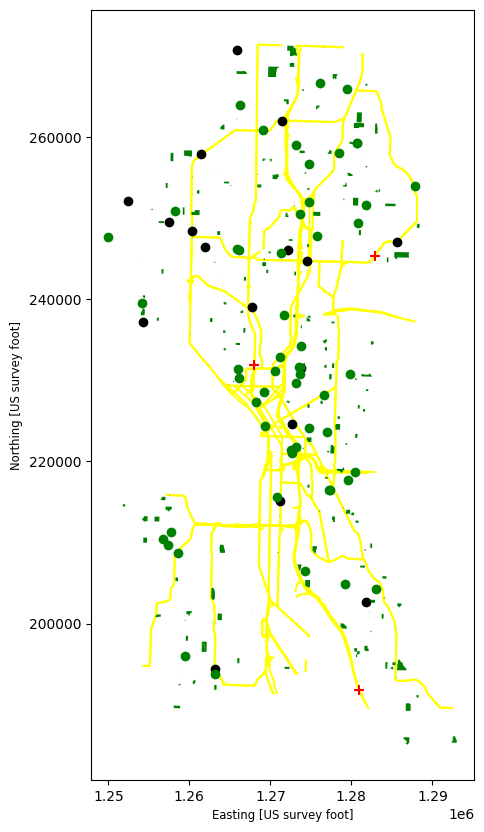

In [378]:
# original suitable roads
base = suitable_roads.plot(color='yellow', figsize=(10, 10),zorder=1)

# non-overlapping buffers
GoodLocationsGas_buffered_gdf.plot(ax=base, edgecolor='red', marker="+", facecolor='none',zorder=2)

# center points of the buffers
GoodLocationsGas_gdf.plot(ax=base, color='red', marker="+", markersize=50,zorder=3)

# all stations
fuelSeattle.plot(ax=base,color='k',zorder=4)
schoolSeattle.plot(ax=base,color='green',zorder=5)

# stations to relocate
fuelSeattle.clip(gas_relocate).plot(ax=base,color='magenta',zorder=5)

In [379]:
print("fuel:   ", fuelSeattle.crs)
print("school: ", schoolSeattle.crs)
print("roads:  ", suitable_roads.crs)
print("buffers:", GoodLocationsGas_buffered_gdf.crs)

print(fuelSeattle.total_bounds)
print(schoolSeattle.total_bounds)
print(suitable_roads.total_bounds)

fuel:    EPSG:2926
school:  EPSG:2926
roads:   PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",47],PARAMETER["central_meridian",-120.833333333333],PARAMETER["standard_parallel_1",47.5],PARAMETER["standard_parallel_2",48.7333333333333],PARAMETER["false_easting",1640416.66666667],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
buffers: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEOGCS["NAD83(HARN)",DATUM["NAD83_High_Accuracy_Reference_Network",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6152"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lamb


Geocodificación inversa

In [392]:
from geopy.geocoders import Nominatim
import time

# Initialize geocoder
geolocator = Nominatim(user_agent="seattle_gas_stations")

def get_address(point):
  # Now coordinates are in degrees (lon, lat)
  lon = point.x
  lat = point.y
  location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
  time.sleep(1)  # Rate limiting

  if location:
    return location.address
  else:
    return None # not found

In [393]:
# Get addresses
GoodLocationsGas_4326 = GoodLocationsGas_gdf.to_crs('EPSG:4326')
GoodLocationsGas_gdf['address'] = GoodLocationsGas_4326.geometry.apply(get_address)

In [394]:
GoodLocationsGas_gdf

,geometry,address
0,POINT (1268031.118 231936.693),"718, Aurora Avenue North, South Lake Union, Ca..."
0,POINT (1280925.651 191751.964),"I 5, South Beacon Hill, Seattle, King County, ..."
0,POINT (1282884.497 245370.866),"4701, Sand Point Way Northeast, Bryant, Laurel..."
